### Imports

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F

import numpy as np
import math
import random

import tqdm.notebook
from tqdm.notebook import trange

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cuda


### TicTacToe Game

In [2]:
class TicTacToe:
    def __init__(self):
        self.row_ct = 3
        self.col_ct = 3
        self.action_sz = self.row_ct * self.col_ct

    def get_initial_state(self):
        return np.zeros((self.row_ct, self.col_ct))

    def get_next_state(self, state, action, player):
        row = action // self.col_ct
        col = action % self.col_ct
        state[row][col] = player
        return state

    def get_legal_moves(self, state):
        return (state.reshape(-1) == 0).astype(np.uint8) #bool -> uint

    def check_win(self, state, action):
        if action is None:
            return False

        row = action // self.col_ct
        col = action % self.col_ct
        player = state[row][col]

        return (
            np.sum(state[row, :]) == player*self.col_ct # 3 in a row
            or
            np.sum(state[:, col]) == player*self.row_ct # 3 in a col
            or 
            np.sum(np.diag(state)) == player*self.col_ct # diag
            or 
            np.sum(np.diag(np.flip(state, axis = 0))) == player*self.col_ct # opp diag
        )

    def get_val_and_terminated(self, state, action):
        if self.check_win(state, action):
            return 1, True
        if np.sum(self.get_legal_moves(state)) == 0:
            return 0, True
        return 0, False

    def __repr__(self):
        return "TicTacToe"

    def get_opponent(self, player):
        return -player

    def get_opponent_value(self, value):
        return -value

    def change_perspective(self, state, player):
        return state * player #flips the state not the player
    

    def get_encoded_state(self, state):
        return np.stack((state == -1, state == 0, state == 1)).astype(np.float32)


### Testing loop

In [6]:
t = TicTacToe()
player = 1

state = t.get_initial_state()

while True:
    print(state)
    valid = t.get_legal_moves(state)
    print(f"valid moves: {[i for i, x in enumerate(valid) if x == 1]}")

    action = int(input(f"{player}: "))
    if valid[action] == 0:
        print("invalid action")
        continue

    state = t.get_next_state(state, action, player)
    value, terminated = t.get_val_and_terminated(state, action)

    if terminated:
        print(state)
        if value == 1:
            print(f"winner: {player}")
        else:
            print("draw")
        break

    player = t.get_opponent(player)    

[[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]]
valid moves: [0, 1, 2, 3, 4, 5, 6, 7, 8]
[[1. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]]
valid moves: [1, 2, 3, 4, 5, 6, 7, 8]
[[ 1.  0. -1.]
 [ 0.  0.  0.]
 [ 0.  0.  0.]]
valid moves: [1, 3, 4, 5, 6, 7, 8]
[[ 1.  0. -1.]
 [ 0.  1.  0.]
 [ 0.  0.  0.]]
valid moves: [1, 3, 5, 6, 7, 8]
[[ 1.  0. -1.]
 [ 0.  1. -1.]
 [ 0.  0.  0.]]
valid moves: [1, 3, 6, 7, 8]
[[ 1.  0. -1.]
 [ 0.  1. -1.]
 [ 0.  0.  1.]]
winner: 1


### MCTS w Random rollouts

In [10]:
class Node:
    def __init__(self, game, args, state, parent=None, action_taken = None):
        self.game = game
        self.args = args
        self.state = state
        self.parent = parent
        self.action_taken = action_taken

        self.children = []
        self.expandable_moves = game.get_legal_moves(state)

        self.visit_count = 0
        self.value_sum = 0

    def is_fully_expanded(self):
        return np.sum(self.expandable_moves) == 0 and len(self.children) > 0


    def select(self):
        best_child = None
        best_ucb = -np.inf

        for child in self.children:
            ucb = self.get_ucb(child)
            if ucb > best_ucb:
                best_ucb = ucb
                best_child = child

        return best_child


    def get_ucb(self, child):
        q = 1 - ((child.value_sum / child.visit_count) + 1) / 2     # child is opposite player so bad position preferred
        
        return q + self.args['C'] * math.sqrt(math.log(self.visit_count)/child.visit_count)



    def expand(self):
        action = np.random.choice(np.where(self.expandable_moves == 1)[0]) # choose a legal move
        self.expandable_moves[action] = 0

        child_state = self.state.copy()
        child_state = self.game.get_next_state(child_state, action, 1)
        child_state = self.game.change_perspective(child_state, player = -1) # flips pov frmo -1 -> 1

        child = Node(self.game, self.args, child_state, self, action)
        self.children.append(child)
        return child


    def simulate(self):
        value, terminated = self.game.get_val_and_terminated(self.state, self.action_taken)
        value = self.game.get_opponent_value(value)

        if terminated:
            return value

        #perform rollout

        rollout_state = self.state.copy()
        rollout_player = 1

        while True:
            valid_moves = self.game.get_legal_moves(rollout_state)
            action = np.random.choice(np.where(valid_moves == 1)[0])
            rollout_state = self.game.get_next_state(rollout_state, action, rollout_player)
            
            value, terminated = self.game.get_val_and_terminated(rollout_state, action)
            if terminated:
                if rollout_player == -1:
                    value = self.game.get_opponent_value(value)
                return value

            rollout_player = self.game.get_opponent(rollout_player)


    def backprop(self, value):
        self.value_sum += value
        self.visit_count += 1

        value = self.game.get_opponent_value(value)
        if self.parent is not None:
            self.parent.backprop(value)



class MCTSrandom:
    def __init__(self, game, args):
        self.game = game
        self.args = args

    def search(self, state):
        root = Node(self.game, self.args, state)
        
        for search in range(self.args['num_searches']):
            node = root

            while node.is_fully_expanded():
                node = node.select() # selection

            value, terminated = self.game.get_val_and_terminated(node.state, node.action_taken)
            value = self.game.get_opponent_value(value)

            if not terminated: # leaf node + non terminated game = expand + simulate
                node = node.expand() #expansion
                value = node.simulate() # simulate

            node.backprop(value) #backprop
        
        action_prob = np.zeros(self.game.action_sz)
        for child in root.children:
            action_prob[child.action_taken] = child.visit_count

        action_prob /= np.sum(action_prob)
        return action_prob

#### MCTS with random rollouts is able to perform well as tictactoe is solvable for small enough num_searches. Hence signal is noisy but correct

In [11]:
t = TicTacToe()
player = 1

args  = {
    'C':1.41,
    'num_searches':1000
}

mcts = MCTSrandom(t, args)

state = t.get_initial_state()

while True:
    print(state)


    if player == 1:
        valid = t.get_legal_moves(state)
        print(f"valid moves: {[i for i, x in enumerate(valid) if x == 1]}")
        action = int(input(f"{player}: "))
        
        if valid[action] == 0:
            print("invalid action")
            continue
    
    else:
        neutral_state = t.change_perspective(state, player)
        mcts_probs = mcts.search(neutral_state)
        action = np.argmax(mcts_probs)


    state = t.get_next_state(state, action, player)
    value, terminated = t.get_val_and_terminated(state, action)

    if terminated:
        print(state)
        if value == 1:
            print(f"winner: {player}")
        else:
            print("draw")
        break

    player = t.get_opponent(player)    

[[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]]
valid moves: [0, 1, 2, 3, 4, 5, 6, 7, 8]
[[1. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]]
[[ 1.  0.  0.]
 [ 0. -1.  0.]
 [ 0.  0.  0.]]
valid moves: [1, 2, 3, 5, 6, 7, 8]
[[ 1.  0.  0.]
 [ 0. -1.  0.]
 [ 0.  0.  1.]]
[[ 1.  0.  0.]
 [ 0. -1. -1.]
 [ 0.  0.  1.]]
valid moves: [1, 2, 3, 6, 7]
[[ 1.  0.  0.]
 [ 1. -1. -1.]
 [ 0.  0.  1.]]
[[ 1.  0.  0.]
 [ 1. -1. -1.]
 [-1.  0.  1.]]
valid moves: [1, 2, 7]
[[ 1.  0.  1.]
 [ 1. -1. -1.]
 [-1.  0.  1.]]
[[ 1. -1.  1.]
 [ 1. -1. -1.]
 [-1.  0.  1.]]
valid moves: [7]
[[ 1. -1.  1.]
 [ 1. -1. -1.]
 [-1.  1.  1.]]
draw


### Model 

In [12]:
class ResNet(nn.Module):
    def __init__(self, game, num_resblocks, num_hidden, device):
        super().__init__()
        self.device = device # remembered so MCTS / training can send inputs to the same place

        self.startBlock = nn.Sequential(
            nn.Conv2d(3, num_hidden, kernel_size=3, padding=1),
            nn.BatchNorm2d(num_hidden),
            nn.ReLU(),
        )

        self.backbone = nn.ModuleList(
            [ResBlock(num_hidden) for _ in range(num_resblocks)]
        )

        self.policy_head = nn.Sequential(
            nn.Conv2d(num_hidden, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Flatten(),
            nn.Linear(32* game.row_ct * game.col_ct, game.action_sz)
        )

        self.value_head = nn.Sequential(
            nn.Conv2d(num_hidden, 3, kernel_size=3, padding=1),
            nn.BatchNorm2d(3),
            nn.ReLU(),
            nn.Flatten(),
            nn.Linear(3 * game.row_ct * game.col_ct , 1),
            nn.Tanh()
        )

        self.to(device) # move all weights to the GPU (or CPU)

    def forward(self, x):
        x = self.startBlock(x)
        for resBlock in self.backbone:
            x = resBlock(x)

        policy = self.policy_head(x)
        value = self.value_head(x)
        return policy, value



class ResBlock(nn.Module):
    def __init__(self, num_hidden):
        super().__init__()
        self.conv1 = nn.Conv2d(num_hidden, num_hidden, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(num_hidden)
        self.conv2 = nn.Conv2d(num_hidden, num_hidden, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(num_hidden)

    def forward(self, x):
        residual = x    
        x = self.conv1(x)
        x = self.bn1(x)
        x = F.relu(x)
        x = self.conv2(x)
        x = self.bn2(x)
        x = x + residual
        x = F.relu(x)
        return x

### MCTS w Model

In [13]:
class Node:
    def __init__(self, game, args, state, parent=None, action_taken = None, prior = 0, visit_count = 0):
        self.game = game
        self.args = args
        self.state = state
        self.parent = parent
        self.action_taken = action_taken
        self.prior = prior # prior added

        self.children = []

        self.visit_count = visit_count
        self.value_sum = 0

    def is_fully_expanded(self):
        return len(self.children) > 0


    def select(self):
        best_child = None
        best_ucb = -np.inf

        for child in self.children:
            ucb = self.get_ucb(child)
            if ucb > best_ucb:
                best_ucb = ucb
                best_child = child

        return best_child


    def get_ucb(self, child): #updated ucb
        if child.visit_count == 0:
            q = 0
        else:
            q = 1 - ((child.value_sum / child.visit_count) + 1)/2

        return q + self.args['C'] * child.prior * math.sqrt(self.visit_count) / (1 + child.visit_count)



    def expand(self, policy):

        for action, prob in enumerate(policy):
            if prob > 0:
                child_state = self.state.copy()
                child_state = self.game.get_next_state(child_state, action, 1)
                child_state = self.game.change_perspective(child_state, player = -1) # flips pov frmo -1 -> 1
                child = Node(self.game, self.args, child_state, self, action, prob)
                self.children.append(child)



    def backprop(self, value):
        self.value_sum += value
        self.visit_count += 1

        value = self.game.get_opponent_value(value)
        if self.parent is not None:
            self.parent.backprop(value)



class MCTS:
    def __init__(self, game, args, model):
        self.game = game
        self.args = args
        self.model = model # added model 


    @torch.no_grad() # no need for gradients during mcts
    def search(self, state):
        root = Node(self.game, self.args, state, visit_count = 1)

        policy, value = self.model(torch.tensor(self.game.get_encoded_state(state), device=self.model.device).unsqueeze(0))
        policy = torch.softmax(policy, axis=-1).squeeze(0).cpu().numpy()

        #add drichlet noise for exploration: one alpha per move -> [eta] * action_sz
        policy = (1 - self.args['epsilon']) * policy + \
            self.args['epsilon'] * np.random.dirichlet([self.args['dirichlet_eta']] * self.game.action_sz)
        
        valid_moves = self.game.get_legal_moves(state)
        policy = policy * valid_moves
        policy = policy / np.sum(policy)
        root.expand(policy)
        
        for search in range(self.args['num_searches']):
            node = root

            while node.is_fully_expanded():
                node = node.select() # selection

            value, terminated = self.game.get_val_and_terminated(node.state, node.action_taken)
            value = self.game.get_opponent_value(value)

            if not terminated: # leaf node + non terminated game = expand + simulate

                #integrated model to mcts
                encoded = torch.tensor(self.game.get_encoded_state(node.state), device=self.model.device).unsqueeze(0) # input on same device as model
                policy, value = self.model(encoded)
                
                policy = torch.softmax(policy, dim = 1).squeeze(0).cpu().numpy() # back to cpu for numpy
                valid_moves = self.game.get_legal_moves(node.state)
                policy = policy*valid_moves #mask
                policy /= np.sum(policy)

                value = value.item() # gets flota from tensor

                node.expand(policy) #expansion


            node.backprop(value) #backprop != optimizer.backprop()
        
        action_prob = np.zeros(self.game.action_sz)
        for child in root.children:
            action_prob[child.action_taken] = child.visit_count

        action_prob /= np.sum(action_prob)
        return action_prob

In [14]:
t = TicTacToe()
player = 1

args  = {
    'C':1.41,
    'num_searches':1000,
    'epsilon': 0,          # no exploration noise when playing
    'dirichlet_eta': 0.3,
}

model = ResNet(t, 4, 64, device) # untrained model (see the play cell after training for the trained one)
model.eval()
mcts = MCTS(t, args, model)
state = t.get_initial_state()

while True:
    print(state)


    if player == 1:
        valid = t.get_legal_moves(state)
        print(f"valid moves: {[i for i, x in enumerate(valid) if x == 1]}")
        action = int(input(f"{player}: "))
        
        if valid[action] == 0:
            print("invalid action")
            continue
    
    else:
        neutral_state = t.change_perspective(state, player)
        mcts_probs = mcts.search(neutral_state)
        action = np.argmax(mcts_probs)


    state = t.get_next_state(state, action, player)
    value, terminated = t.get_val_and_terminated(state, action)

    if terminated:
        print(state)
        if value == 1:
            print(f"winner: {player}")
        else:
            print("draw")
        break

    player = t.get_opponent(player)    

[[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]]
valid moves: [0, 1, 2, 3, 4, 5, 6, 7, 8]
[[1. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]]
[[ 1.  0.  0.]
 [ 0.  0.  0.]
 [-1.  0.  0.]]
valid moves: [1, 2, 3, 4, 5, 7, 8]
[[ 1.  0.  0.]
 [ 0.  0.  0.]
 [-1.  0.  1.]]
[[ 1.  0.  0.]
 [ 0. -1.  0.]
 [-1.  0.  1.]]
valid moves: [1, 2, 3, 5, 7]
[[ 1.  0.  1.]
 [ 0. -1.  0.]
 [-1.  0.  1.]]
[[ 1.  0.  1.]
 [ 0. -1. -1.]
 [-1.  0.  1.]]
valid moves: [1, 3, 7]
[[ 1.  1.  1.]
 [ 0. -1. -1.]
 [-1.  0.  1.]]
winner: 1


Model is untrained and lost

#### Added:
- GPU as a device
- Temperature
- Noise 

In [15]:
class AlphaZero:
    def __init__(self, model, optimizer, game, args):
        self.model = model
        self.optimizer = optimizer
        self.game = game
        self.args = args
        self.mcts = MCTS(game, args, model)
        self.loss_history = [] # one entry per epoch: {'iteration', 'epoch', 'policy', 'value', 'total'}

    def selfPlay(self):
        memory = []
        player = 1
        state = self.game.get_initial_state()

        while True:
            neutral_state = self.game.change_perspective(state, player)
            action_probs = self.mcts.search(neutral_state)
            
            memory.append((neutral_state, action_probs, player)) # one tuple

            temperature_action = action_probs ** (1 / self.args['temperature'])
            temperature_action /= np.sum(temperature_action) # must sum to 1 for np.random.choice
            action = np.random.choice(self.game.action_sz, p = temperature_action)

            state = self.game.get_next_state(state, action, player)
            value, terminated = self.game.get_val_and_terminated(state, action)

            if terminated:
                returnmem = []
                for h_state, h_prob, h_player in memory:
                    h_win = value if h_player == player else self.game.get_opponent_value(value)
                    returnmem.append((self.game.get_encoded_state(h_state), h_prob, h_win)) # tuple, not set

                return returnmem

            player = self.game.get_opponent(player)


    # the NN does NOT use MCTS here: MCTS already ran in selfPlay and produced policy_target
    def train(self, memory):
        random.shuffle(memory)
        policy_sum, value_sum, n = 0.0, 0.0, 0 # for the average loss over this epoch

        for batchIdx in range(0, len(memory), self.args['batch_size']):
            sample = memory[batchIdx : batchIdx + self.args['batch_size']]
            state, policy_target, value_target = zip(*sample)

            state, policy_target, value_target = np.array(state), np.array(policy_target), np.array(value_target).reshape(-1, 1)

            state = torch.tensor(state, dtype=torch.float32, device=self.model.device) # same dtype + device as the weights
            policy_target = torch.tensor(policy_target, dtype=torch.float32, device=self.model.device)
            value_target = torch.tensor(value_target, dtype=torch.float32, device=self.model.device)

            policy_pred, value_pred = self.model(state)

            policy_loss = F.cross_entropy(policy_pred, policy_target)
            value_loss = F.mse_loss(value_pred, value_target)
            loss = policy_loss + value_loss  # L2 is applied by the optimizer's weight_decay

            self.optimizer.zero_grad()
            loss.backward()
            self.optimizer.step()

            # weight each batch by its size (the last batch can be smaller)
            policy_sum += policy_loss.item() * len(sample)
            value_sum += value_loss.item() * len(sample)
            n += len(sample)

        return policy_sum / n, value_sum / n


    def learn(self):
        for iteration in trange(self.args['num_iterations']):
            memory = []

            self.model.eval()
            for i in trange(self.args['num_selfPlay_iterations']):
                memory += self.selfPlay()

            self.model.train()
            for e in trange(self.args['num_epochs']):
                policy_loss, value_loss = self.train(memory)
                self.loss_history.append({
                    'iteration': iteration, 'epoch': e,
                    'policy': policy_loss, 'value': value_loss, 'total': policy_loss + value_loss,
                })

            torch.save(self.model.state_dict(), f"model_{iteration}_{self.game}.pt")
            torch.save(self.optimizer.state_dict(), f"optimizer_{iteration}_{self.game}.pt")
            np.save(f"loss_history_{self.game}.npy", self.loss_history) # saved every iteration, so a stopped run still has its curve


In [17]:
t = TicTacToe()
model = ResNet(t, 4, 64, device)

# weight_decay = L2 regularisation (the c·||θ||² term in the AlphaZero loss)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=0.0001)

args = {
    'C': 2,
    'num_searches': 60,
    'num_iterations': 3,
    'num_selfPlay_iterations': 200,   # ~50 min per iteration; use 200 for ~20 min
    'num_epochs': 4,
    'batch_size': 64,
    'temperature': 1.25,
    'epsilon': 0.25,          # weight of the Dirichlet noise at the root
    'dirichlet_eta': 0.3,     # Dirichlet alpha
}

alphaZero = AlphaZero(model, optimizer, t, args)
alphaZero.learn()

  0%|          | 0/3 [00:00<?, ?it/s]

  0%|          | 0/200 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/200 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/200 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

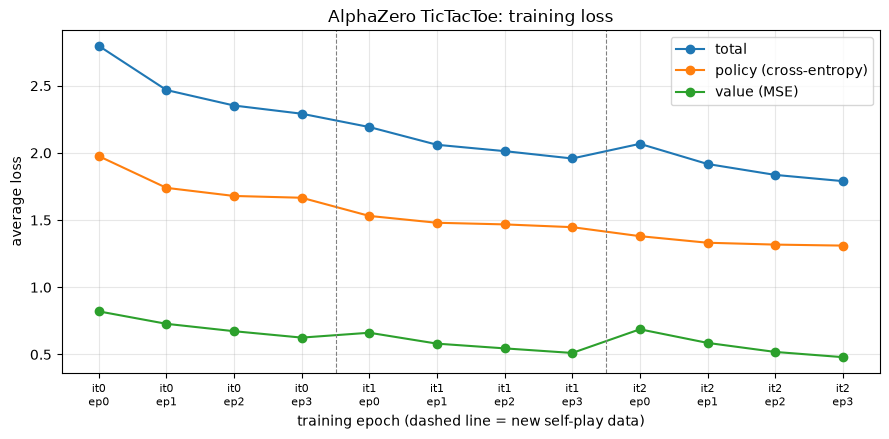

In [18]:
# loss curve (run after training; also works later from the saved file)
import matplotlib.pyplot as plt

try:
    history = alphaZero.loss_history
except NameError:
    history = list(np.load("loss_history_TicTacToe.npy", allow_pickle=True))

x = np.arange(len(history))
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(x, [h['total'] for h in history], marker='o', label='total')
ax.plot(x, [h['policy'] for h in history], marker='o', label='policy (cross-entropy)')
ax.plot(x, [h['value'] for h in history], marker='o', label='value (MSE)')

# dashed line where each new iteration (= new self-play data) starts
for i, h in enumerate(history):
    if h['epoch'] == 0 and i > 0:
        ax.axvline(i - 0.5, color='gray', linestyle='--', linewidth=0.8)

ax.set_xticks(x)
ax.set_xticklabels([f"it{h['iteration']}\nep{h['epoch']}" for h in history], fontsize=8)
ax.set_xlabel('training epoch (dashed line = new self-play data)')
ax.set_ylabel('average loss')
ax.set_title('AlphaZero TicTacToe: training loss')
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

In [21]:
# play against the TRAINED model (run after training has saved model_2_TicTacToe.pt)
t = TicTacToe()
player = 1          # player 1 always moves first
human = -1          # -1 = bot first, 1 = human first

args = {
    'C': 2,
    'num_searches': 100,
    'epsilon': 0,          # no exploration noise when playing
    'dirichlet_eta': 0.3,
}

model = ResNet(t, 4, 64, device)
model.load_state_dict(torch.load("model_2_TicTacToe.pt", map_location=device))
model.eval()
mcts = MCTS(t, args, model)
state = t.get_initial_state()

while True:
    print(state)

    if player == human:
        valid = t.get_legal_moves(state)
        print(f"valid moves: {[i for i, x in enumerate(valid) if x == 1]}")
        action = int(input(f"{player}: "))

        if valid[action] == 0:
            print("invalid action")
            continue

    else:
        neutral_state = t.change_perspective(state, player)
        mcts_probs = mcts.search(neutral_state)
        action = np.argmax(mcts_probs)

    state = t.get_next_state(state, action, player)
    value, terminated = t.get_val_and_terminated(state, action)

    if terminated:
        print(state)
        if value == 1:
            print("winner:", "you" if player == human else "bot")
        else:
            print("draw")
        break

    player = t.get_opponent(player)

[[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]]
[[1. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]]
valid moves: [1, 2, 3, 4, 5, 6, 7, 8]
[[ 1.  0.  0.]
 [ 0.  0.  0.]
 [ 0.  0. -1.]]
[[ 1.  0.  0.]
 [ 0.  0.  0.]
 [ 1.  0. -1.]]
valid moves: [1, 2, 3, 4, 5, 7]
[[ 1.  0.  0.]
 [-1.  0.  0.]
 [ 1.  0. -1.]]
[[ 1.  0.  1.]
 [-1.  0.  0.]
 [ 1.  0. -1.]]
valid moves: [1, 4, 5, 7]
[[ 1. -1.  1.]
 [-1.  0.  0.]
 [ 1.  0. -1.]]
[[ 1. -1.  1.]
 [-1.  1.  0.]
 [ 1.  0. -1.]]
winner: bot


#### Bot always wins or ties

--------------